# 03 · Event reconstruction and OFI (Day 1: Stage-0 close-out + Stage 1)
**Microstructure Alpha · Binance USD-M ETHUSDT perpetual · 7–14 Sep 2026**

| Section | What it does |
|---|---|
| 1 | Main pass: for every update batch, the **touch decomposition** (executions, net adds/cancels, price-level moves), **level 1–10 OFI** and trade flow. Rebuilds **taker orders** from consecutive fills. Saves the **event store** |
| 2 | **Stage-0 close-out**: tests *why* 0.94% of trades were unexplained in notebook 02 (timestamp drift vs changes inside a batch), and re-runs the order-walk check per taker order, the unit it should have used |
| 3 | **Six hand-checked batches**: real batches of each type, with the arithmetic printed so you can verify it by hand. Values must match the expected numbers computed independently |
| 4 | Event and OFI summary: OFI decomposition, taker orders, queue composition from fill sizes |

### Definitions
**Level-ℓ OFI** (Cont–Kukanov–Stoikov), per batch, with *p* = pre-state and *n* = post-state:
e = 1{Pb_n ≥ Pb_p}·qb_n − 1{Pb_n ≤ Pb_p}·qb_p − 1{Pa_n ≤ Pa_p}·qa_n + 1{Pa_n ≥ Pa_p}·qa_p, applied to the ℓ-th level of each side.

**Touch decomposition** (per side). If the touch price is unchanged: Δq = q_post − q_pre, V = executions at that price in the batch, **N = Δq + V** (net limit-order change: >0 net adds, <0 net cancels). If the price moved: `improve` (a better price appeared), `sweep_out` (V ≥ q_pre: executions emptied the level) or `cancel_out` (the level vanished without enough trading).

**Exact identity** checked on every batch: level-1 OFI = **limit flow** (N_bid − N_ask on unchanged sides) + **market flow** (V_ask − V_bid on unchanged sides) + **move flow** (+qb_n for a bid improvement, −qb_p for a bid drop, −qa_n for an ask improvement, +qa_p for an ask retreat).

**Taker order** = consecutive trade IDs with the same timestamp and side. Each fill is one resting maker order at the front of the queue, so fill sizes show the real queue composition.

**Limitation:** adds and cancels inside one ~27 ms batch net out. N is exact, but separate add and cancel volumes are lower bounds. OFI only needs the net, so it is unaffected.

**Inputs:** notebook 01 book files, notebook 02 trade files and reports. **Runtime:** about 15–20 minutes. **Disk:** about 1–1.5 GB for the event store.

In [1]:
# ===================== CONFIG — same paths as notebooks 01–02 =====================
from pathlib import Path
OUT_DIR  = Path(r"C:\microalpha_proj\microoutput")
DATES    = [f"2026-09-{d:02d}" for d in range(7, 15)]
K_LEVELS = 10
TOL_KMAX = 5                    # timestamp-tolerance scan: ± batches
HANDCHECK = ('2026-09-07', 6)   # hour used for the six hand-checked batches (expected values below are for this hour)
# Stage-0 close-out criteria, fixed BEFORE running on all days:
RES_QUIET_MAX      = 0.0005     # unexplained rate in batches where the mid moved ≤ 1 tick, every day
RES_FAST_SHARE_MIN = 0.80       # share of unexplained trades in batches where the mid moved ≥ 4 ticks, every day
ORDER_MONO_MIN     = 0.99       # taker orders whose fills walk the book in price order, every day
STRICT   = True
# ===================================================================================

In [2]:
import sys, time, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import ma_lib
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)
REP, BOOK, TRD, EVT = OUT_DIR / 'reports', OUT_DIR / 'book', OUT_DIR / 'trades', OUT_DIR / 'events'
EVT.mkdir(exist_ok=True)
EXPECTED = {'plain_fill': {'u': 11494470996910, 'ofi1': 215, 'limit': 0, 'market': 215, 'move': 0, 'ofi2': 0}, 'sweep_empties_level': {'u': 11494475341171, 'ofi1': 325547, 'limit': 0, 'market': 0, 'move': 325547, 'ofi2': 43833}, 'cancel_at_touch': {'u': 11494470570827, 'ofi1': -13, 'limit': -13, 'market': 0, 'move': 0, 'ofi2': 0}, 'improvement_into_spread': {'u': 11494602279899, 'ofi1': 156165, 'limit': -27, 'market': 0, 'move': 156192, 'ofi2': 1949}, 'mixed_fill_and_add': {'u': 11494471326283, 'ofi1': 15, 'limit': -8, 'market': 23, 'move': 0, 'ofi2': 0}, 'deep_level_only': {'u': 11494470928405, 'ofi1': 0, 'limit': 0, 'market': 0, 'move': 0, 'ofi2': -778}}
miss = [d for d in DATES if not (TRD / f'trades_{d}.parquet').exists()] + \
       [f'{d} {h:02d}' for d in DATES for h in range(24) if not (BOOK / d / f'book_{d}_{h:02d}.parquet').exists()]
print('missing inputs:', miss or 'none')
if STRICT and miss: raise RuntimeError('run notebooks 01 and 02 first')

missing inputs: none


## 1 · Main pass: events, OFI and taker orders
Writes `events/<date>/events_<date>_<HH>.parquet` (one row per batch) and `events/taker_orders_<date>.parquet`.

Event columns: `u, T, R, ok` (valid pre- and post-state), `seg, bp1, ap1, bq1, aq1`, `ofi1..ofi10` (lots), `limit_flow, market_flow, move_flow`, `mv_b, mv_a` (0 unchanged, 1 improve, 2 sweep_out, 3 cancel_out), `N_b, N_a, V_b_touch, V_a_touch, v_buy, v_sell, n_buy_fills, n_sell_fills`.

In [3]:
BUCKETS = [-0.1, 0.5, 1.5, 3.5, 10.5, 1e9]; BLAB = ['0', '1', '2-3', '4-10', '>10']
t_start = time.time()
day_stats, bucket_rows, tol_rows, order_days = [], [], [], []
prev_tail, carry = None, None
for date in DATES:
    t0 = time.time()
    trd = pd.read_parquet(TRD / f'trades_{date}.parquet')
    tr_all = trd if carry is None else pd.concat([carry, trd], ignore_index=True)
    j = tr_all[tr_all.u_post >= 0].sort_values('u_post', kind='stable')
    up = j.u_post.to_numpy()
    orders = ma_lib.build_taker_orders(trd)
    orders['touch_px_pre'] = 0; orders['touch_q_pre'] = 0; orders['emptied_touch'] = False
    oup = orders.u_post.to_numpy()
    S = dict(date=date, batches=0, ok=0, identity_violations=0, ofi_nonzero=0, trade_growth_b=0, trade_growth_a=0,
             touch_trading_b=0, touch_trading_a=0, s_oo=0.0, s_ol=0.0, s_om=0.0, s_ov=0.0, s_o=0.0, s_l=0.0, s_m=0.0, s_v=0.0)
    for c in range(4): S[f'mv_b_{c}'] = 0; S[f'mv_a_{c}'] = 0
    bucket = np.zeros((len(BLAB), 2)); env_un = env_all = n_un = n_all = 0; khist = {}
    last_u = -1
    for hour in range(24):
        bpath = BOOK / date / f'book_{date}_{hour:02d}.parquet'
        if not bpath.exists(): prev_tail = None; continue
        book = pd.read_parquet(bpath)
        lo, hi = np.searchsorted(up, book.u.iloc[0], 'left'), np.searchsorted(up, book.u.iloc[-1], 'right')
        trh = j.iloc[lo:hi]
        ev, _ = ma_lib.batch_events(book, prev_tail, trh, K_LEVELS)
        (EVT / date).mkdir(exist_ok=True)
        ev.to_parquet(EVT / date / f'events_{date}_{hour:02d}.parquet', compression='zstd', index=False)
        v = ev[ev.ok]
        o, l, m_, mv = (v[c].to_numpy(np.float64) for c in ('ofi1', 'limit_flow', 'market_flow', 'move_flow'))
        S['batches'] += len(ev); S['ok'] += len(v)
        S['identity_violations'] += int((ev.ofi1 != ev.limit_flow + ev.market_flow + ev.move_flow).sum())
        S['ofi_nonzero'] += int((v.ofi1 != 0).sum())
        S['s_oo'] += (o * o).sum(); S['s_ol'] += (o * l).sum(); S['s_om'] += (o * m_).sum(); S['s_ov'] += (o * mv).sum()
        S['s_o'] += o.sum(); S['s_l'] += l.sum(); S['s_m'] += m_.sum(); S['s_v'] += mv.sum()
        for c in range(4): S[f'mv_b_{c}'] += int((v.mv_b == c).sum()); S[f'mv_a_{c}'] += int((v.mv_a == c).sum())
        tb, ta = (v.mv_b == 0) & (v.V_b_touch > 0), (v.mv_a == 0) & (v.V_a_touch > 0)
        S['touch_trading_b'] += int(tb.sum()); S['touch_trading_a'] += int(ta.sum())
        S['trade_growth_b'] += int((tb & (v.N_b > 0)).sum()); S['trade_growth_a'] += int((ta & (v.N_a > 0)).sum())
        # Stage-0 diagnostics on usable trades
        use = trh[trh.cls >= 0]
        if len(use):
            env, dm = ma_lib.unexplained_diagnostics(book, prev_tail, use)
            un = use.cls.isin([4, 5, 6]).to_numpy()
            bidx = np.digitize(dm, BUCKETS[1:-1], right=True)
            np.add.at(bucket, (bidx, 0), 1); np.add.at(bucket, (bidx[un], 1), 1)
            env_un += int(env[un].sum()); env_all += int(env.sum()); n_un += int(un.sum()); n_all += len(use)
            if un.any():
                kk = ma_lib.tolerance_scan(book, prev_tail, use[un], K_LEVELS, TOL_KMAX)
                for k_, c_ in zip(*np.unique(kk, return_counts=True)): khist[int(k_)] = khist.get(int(k_), 0) + int(c_)
        # taker-order touch state
        olo, ohi = np.searchsorted(oup, book.u.iloc[0], 'left'), np.searchsorted(oup, book.u.iloc[-1], 'right')
        if ohi > olo:
            tpx, tq, emp = ma_lib.attach_touch(orders.iloc[olo:ohi], book, prev_tail)
            orders.iloc[olo:ohi, orders.columns.get_loc('touch_px_pre')] = tpx
            orders.iloc[olo:ohi, orders.columns.get_loc('touch_q_pre')] = tq
            orders.iloc[olo:ohi, orders.columns.get_loc('emptied_touch')] = emp
        prev_tail = book.iloc[-(TOL_KMAX + 2):]
        last_u = int(book.u.iloc[-1])
        del book, ev
    carry = trd[trd.u_post > last_u] if last_u >= 0 else None
    orders.to_parquet(EVT / f'taker_orders_{date}.parquet', compression='zstd', index=False)
    fills = trd[trd.cls == 0].qty.to_numpy() / 1000
    S.update(n_unexpl=n_un, n_usable=n_all, env_unexpl=env_un, env_all=env_all,
             orders=len(orders), orders_mono=float(1 - orders.nonmonotone[orders.usable].mean()),
             orders_multi_level=float((orders.n_levels > 1).mean()), orders_emptied=float(orders.emptied_touch.mean()),
             fills_per_order=float(orders.n_fills.mean()), order_eth_median=float(orders.qty.median() / 1000),
             order_eth_p99=float(orders.qty.quantile(.99) / 1000), **{f'fill_eth_p{p}': float(np.percentile(fills, p)) for p in (10, 25, 50, 75, 90, 99)})
    day_stats.append(S)
    for i, b in enumerate(BLAB): bucket_rows.append(dict(date=date, dmid_ticks=b, trades=int(bucket[i, 0]), unexplained=int(bucket[i, 1])))
    tol_rows.append(dict(date=date, **{f'k{k}': c for k, c in sorted(khist.items())}))
    order_days.append(orders.assign(date=date)[['date', 'sign', 'qty', 'n_fills', 'n_levels', 'emptied_touch']])
    print(f"{date}: {S['ok']:>9,} valid batches | identity violations {S['identity_violations']} | orders {len(orders):>9,} "
          f"(walk in order {S['orders_mono']:.3%}) | unexplained {n_un:,} | {time.time()-t0:.0f}s")
ds = pd.DataFrame(day_stats).set_index('date'); bk_ = pd.DataFrame(bucket_rows); tol = pd.DataFrame(tol_rows).set_index('date').fillna(0).astype(int)
ds.to_csv(REP / '03_day_stats.csv'); bk_.to_csv(REP / '03_unexplained_by_dmid.csv', index=False); tol.to_csv(REP / '03_tolerance_scan.csv')
print(f'done in {(time.time()-t_start)/60:.1f} min')

2026-09-07: 3,227,198 valid batches | identity violations 0 | orders   568,213 (walk in order 99.849%) | unexplained 20,484 | 26s
2026-09-08: 3,201,091 valid batches | identity violations 0 | orders   654,943 (walk in order 99.851%) | unexplained 23,491 | 21s
2026-09-09: 3,223,099 valid batches | identity violations 0 | orders   727,827 (walk in order 99.831%) | unexplained 27,830 | 20s
2026-09-10: 3,157,031 valid batches | identity violations 0 | orders   777,812 (walk in order 99.868%) | unexplained 28,465 | 20s
2026-09-11: 3,196,032 valid batches | identity violations 0 | orders 1,355,053 (walk in order 99.685%) | unexplained 154,713 | 26s
2026-09-12: 3,065,286 valid batches | identity violations 0 | orders   356,843 (walk in order 99.860%) | unexplained 8,044 | 17s
2026-09-13: 2,956,100 valid batches | identity violations 0 | orders   511,120 (walk in order 99.843%) | unexplained 18,963 | 17s
2026-09-14: 3,180,219 valid batches | identity violations 0 | orders   909,216 (walk in or

## 2 · Stage-0 close-out: why are ~1% of trades unexplained?
Two explanations predict different things:
- **Timestamp drift** between the trade and depth streams: the trade's price should appear on its side of the book a few batches earlier or later, so widening the tolerance should explain most of them.
- **Changes inside one batch**: liquidity appears and is taken within one ~27 ms batch, so it never shows at a batch boundary. Unexplained trades should then **concentrate in batches where the price jumps**, and be almost absent when the mid is still.

In [4]:
# (a) timestamp tolerance
tol_share = tol.div(tol.sum(axis=1), axis=0)
found_within = {f'|k|<={K}': tol_share[[c for c in tol.columns if c != 'k99' and abs(int(c[1:])) <= K]].sum(axis=1) for K in range(0, TOL_KMAX + 1)}
fw = pd.DataFrame(found_within); fw['never (±%d)' % TOL_KMAX] = tol_share.get('k99', 0)
print('(a) share of unexplained trades whose price appears on their own side within ±k batches:')
display(fw.style.format('{:.1%}'))
# (b) concentration by how far the mid moved in the trade's batch
b = bk_.groupby('dmid_ticks', sort=False)[['trades', 'unexplained']].sum()
b['unexplained_rate'] = b.unexplained / b.trades; b['share_of_unexplained'] = b.unexplained / b.unexplained.sum()
print('(b) all days, by |Δmid| of the batch (ticks):'); display(b.style.format({'unexplained_rate': '{:.4%}', 'share_of_unexplained': '{:.1%}', 'trades': '{:,.0f}', 'unexplained': '{:,.0f}'}))
pv = bk_.pivot(index='date', columns='dmid_ticks', values=['trades', 'unexplained'])
quiet_rate = (pv['unexplained'][['0', '1']].sum(axis=1) / pv['trades'][['0', '1']].sum(axis=1))
fast_share = pv['unexplained'][['4-10', '>10']].sum(axis=1) / pv['unexplained'].sum(axis=1)
close = pd.DataFrame({'quiet_batch_unexplained_rate': quiet_rate, 'share_in_fast_batches': fast_share,
                      'inside_batch_price_range': ds.env_unexpl / ds.n_unexpl, 'taker_orders_walk_in_order': ds.orders_mono})
print('(c) per day:'); display(close.style.format({'quiet_batch_unexplained_rate': '{:.4%}', 'share_in_fast_batches': '{:.1%}',
                                                  'inside_batch_price_range': '{:.1%}', 'taker_orders_walk_in_order': '{:.3%}'}))

(a) share of unexplained trades whose price appears on their own side within ±k batches:


,|k|<=0,|k|<=1,|k|<=2,|k|<=3,|k|<=4,|k|<=5,never (±5)
date,,,,,,,
2026-09-07,0.0%,2.8%,7.0%,9.7%,11.0%,12.1%,87.9%
2026-09-08,0.0%,2.7%,7.6%,10.6%,13.3%,14.8%,85.2%
2026-09-09,0.0%,2.5%,7.0%,10.8%,13.8%,15.4%,84.6%
2026-09-10,0.0%,3.7%,9.1%,12.0%,14.8%,17.4%,82.6%
2026-09-11,0.0%,3.4%,10.7%,16.0%,19.8%,22.9%,77.1%
2026-09-12,0.0%,3.1%,10.9%,13.7%,15.6%,16.4%,83.6%
2026-09-13,0.0%,3.0%,8.5%,12.1%,13.7%,14.9%,85.1%
2026-09-14,0.0%,2.5%,7.4%,11.0%,13.1%,15.1%,84.9%


(b) all days, by |Δmid| of the batch (ticks):


,trades,unexplained,unexplained_rate,share_of_unexplained
dmid_ticks,,,,
0,"8,068,627","11,400",0.1413%,3.5%
1,"703,324","8,737",1.2422%,2.7%
2-3,"884,912","12,236",1.3827%,3.7%
4-10,"5,027,679","41,653",0.8285%,12.7%
>10,"19,995,361","252,895",1.2648%,77.4%


(c) per day:


,quiet_batch_unexplained_rate,share_in_fast_batches,inside_batch_price_range,taker_orders_walk_in_order
date,,,,
2026-09-07,0.1202%,90.8%,66.5%,99.849%
2026-09-08,0.1576%,90.2%,71.8%,99.851%
2026-09-09,0.1066%,90.5%,69.7%,99.831%
2026-09-10,0.1098%,92.2%,67.7%,99.868%
2026-09-11,0.6446%,89.1%,59.1%,99.685%
2026-09-12,0.0795%,90.4%,75.6%,99.860%
2026-09-13,0.1351%,90.2%,72.4%,99.843%
2026-09-14,0.1589%,91.6%,67.7%,99.793%


In [5]:
s02 = (REP / '02_summary.md').read_text(encoding='utf-8').splitlines()
base = [l for l in s02 if l.startswith(('PASS BOOK', 'FAIL BOOK', 'PASS TRADES', 'FAIL TRADES'))]
gate0 = {'notebook 02: every BOOK and TRADES check passed': len(base) > 0 and all(l.startswith('PASS') for l in base),
         'event identity: level-1 OFI == limit + market + move on every batch': int(ds.identity_violations.sum()) == 0,
         f'quiet batches (|Δmid| ≤ 1 tick): unexplained rate ≤ {RES_QUIET_MAX:.2%}, every day': bool((close.quiet_batch_unexplained_rate <= RES_QUIET_MAX).all()),
         f'≥ {RES_FAST_SHARE_MIN:.0%} of unexplained trades in fast batches (|Δmid| ≥ 4 ticks), every day': bool((close.share_in_fast_batches >= RES_FAST_SHARE_MIN).all()),
         f'taker orders walk the book in order ≥ {ORDER_MONO_MIN:.0%}, every day': bool((close.taker_orders_walk_in_order >= ORDER_MONO_MIN).all())}
for k, v in gate0.items(): print(('PASS  ' if v else 'FAIL  ') + k)
verdict = ('PASSED WITH DOCUMENTED LIMITATION' if all(gate0.values()) else 'NOT PASSED')
print(f"\nSTAGE 0: {verdict}")
print("Limitation recorded either way: notebook 02's thresholds (unexplained ≤ 0.5% of trades, ≤ 1% of volume) FAILED; "
      "the order-walk check there used the wrong unit (batch side instead of taker order).")

PASS  notebook 02: every BOOK and TRADES check passed
PASS  event identity: level-1 OFI == limit + market + move on every batch
FAIL  quiet batches (|Δmid| ≤ 1 tick): unexplained rate ≤ 0.05%, every day
PASS  ≥ 80% of unexplained trades in fast batches (|Δmid| ≥ 4 ticks), every day
PASS  taker orders walk the book in order ≥ 99%, every day

STAGE 0: NOT PASSED
Limitation recorded either way: notebook 02's thresholds (unexplained ≤ 0.5% of trades, ≤ 1% of volume) FAILED; the order-walk check there used the wrong unit (batch side instead of taker order).


## 3 · Six hand-checked batches (hour 2026-09-07 06)
For each type, the first such batch in the hour is printed with its pre/post book, its trades and the level-1 OFI arithmetic, term by term. Check by hand that the terms add up. The engine must also agree with an **independent scalar implementation** (`cks_scalar`, plain if-statements) and with the **expected values computed separately** (embedded above).

In [6]:
d_, h_ = HANDCHECK
bookh = pd.read_parquet(BOOK / d_ / f'book_{d_}_{h_:02d}.parquet')
pp = BOOK / d_ / f'book_{d_}_{h_-1:02d}.parquet'
prevh = pd.read_parquet(pp).iloc[-(TOL_KMAX + 2):] if (h_ > 0 and pp.exists()) else None
trdh = pd.read_parquet(TRD / f'trades_{d_}.parquet'); trdh = trdh[trdh.u_post.between(bookh.u.iloc[0], bookh.u.iloc[-1])]
evh = pd.read_parquet(EVT / d_ / f'events_{d_}_{h_:02d}.parquet')
picks = ma_lib.pick_handcheck(evh, exclude_u=bookh.u.iloc[:2].to_numpy())   # first two batches excluded: same picks on any machine
hc = []
for typ in ma_lib.HANDCHECK_TYPES:
    u = picks[typ]; print(f"\n=== {typ}  (u = {u})")
    if u is None: print('  no batch of this type in the hour'); hc.append(dict(type=typ, found=False)); continue
    got = ma_lib.show_batch(bookh, prevh, trdh, evh, u)
    exp = EXPECTED.get(typ, {})
    same = all(got[k] == exp.get(k) for k in ('u', 'ofi1', 'limit', 'market', 'move', 'ofi2')) if exp else None
    hc.append(dict(type=typ, found=True, u=u, engine_eq_scalar=got['ofi1'] == got['scalar'],
                   components_sum=got['limit'] + got['market'] + got['move'] == got['ofi1'], matches_expected=same))
hc = pd.DataFrame(hc); display(hc)
hc_ok = bool(hc.found.all() and hc.engine_eq_scalar.all() and hc.components_sum.all() and hc.matches_expected.all())
print('HAND-CHECK:', 'PASS' if hc_ok else 'FAIL')
hc.to_csv(REP / '03_handcheck.csv', index=False)


=== plain_fill  (u = 11494470996910)
  level            pre bid           pre ask   |          post bid          post ask
  1       2503.67 x 27.972 2503.68 x 182.211   |  2503.67 x 27.972 2503.68 x 181.996
  2        2503.66 x 0.022   2503.69 x 5.294   |   2503.66 x 0.022   2503.69 x 5.294
  3        2503.64 x 0.019   2503.70 x 0.816   |   2503.64 x 0.019   2503.70 x 0.816
  trades in batch: BUY 0.215@2503.68
  level-1 OFI = + 27.972 [Pb_n>=Pb_p: +qb_n] - 27.972 [Pb_n<=Pb_p: -qb_p] - 181.996 [Pa_n<=Pa_p: -qa_n] + 182.211 [Pa_n>=Pa_p: +qa_p]  = +0.215 ETH
  decomposition: limit +0.000 + market +0.215 + move +0.000 = +0.215 | engine ofi1 +0.215 | N_bid +0.000, N_ask +0.000, executions bid 0.000 ask 0.215 | moves bid=unchanged ask=unchanged | ofi2 +0.000 ofi3 +0.000

=== sweep_empties_level  (u = 11494475341171)
  level            pre bid           pre ask   |          post bid          post ask
  1      2503.37 x 164.964  2503.38 x 15.848   | 2503.39 x 309.699   2503.40 x 5.403
  2    

,type,found,u,engine_eq_scalar,components_sum,matches_expected
0,plain_fill,True,11494470996910,True,True,True
1,sweep_empties_level,True,11494475341171,True,True,True
2,cancel_at_touch,True,11494470570827,True,True,True
3,improvement_into_spread,True,11494602279899,True,True,True
4,mixed_fill_and_add,True,11494471326283,True,True,True
5,deep_level_only,True,11494470928405,True,True,True


HAND-CHECK: PASS


## 4 · Event and OFI summary
**OFI decomposition:** each component's share of level-1 OFI variance, Cov(component, OFI) / Var(OFI). The shares add to 100% exactly because of the identity.

In [7]:
nb = ds.ok
var = ds.s_oo / nb - (ds.s_o / nb) ** 2
dec = pd.DataFrame({c: (ds[f's_o{k}'] / nb - (ds.s_o / nb) * (ds[f's_{k}'] / nb)) / var for c, k in (('limit_flow', 'l'), ('market_flow', 'm'), ('move_flow', 'v'))})
summ = pd.DataFrame({'valid_batches': ds.ok, 'ofi_nonzero': ds.ofi_nonzero / ds.ok,
                     'touch_moves_bid': 1 - ds.mv_b_0 / ds.ok, 'touch_moves_ask': 1 - ds.mv_a_0 / ds.ok,
                     'trading_and_growth_at_touch': (ds.trade_growth_b + ds.trade_growth_a) / (ds.touch_trading_b + ds.touch_trading_a),
                     'taker_orders': ds.orders, 'fills_per_order': ds.fills_per_order, 'multi_level_orders': ds.orders_multi_level,
                     'orders_emptying_touch': ds.orders_emptied, 'order_eth_median': ds.order_eth_median, 'order_eth_p99': ds.order_eth_p99})
display(pd.concat([dec.add_prefix('var_share_'), summ], axis=1).style.format('{:.3f}').format({'valid_batches': '{:,.0f}', 'taker_orders': '{:,.0f}'}))
print('queue composition: size of resting orders filled at the touch (ETH), by day:')
display(ds[[c for c in ds.columns if c.startswith('fill_eth_p')]].round(3))

,var_share_limit_flow,var_share_market_flow,var_share_move_flow,valid_batches,ofi_nonzero,touch_moves_bid,touch_moves_ask,trading_and_growth_at_touch,taker_orders,fills_per_order,multi_level_orders,orders_emptying_touch,order_eth_median,order_eth_p99
date,,,,,,,,,,,,,,
2026-09-07,0.152919,0.014694,0.832386,"3,227,198",0.580196,0.014123,0.014127,0.318654,"568,213",6.335409,0.144469,0.156744,0.300000,79.958160
2026-09-08,0.174332,0.012033,0.813635,"3,201,091",0.615246,0.016666,0.016663,0.330502,"654,943",6.496098,0.151254,0.163468,0.304000,89.984740
2026-09-09,0.183922,0.011390,0.804689,"3,223,099",0.625263,0.018868,0.018875,0.328690,"727,827",6.440460,0.155063,0.167470,0.290000,89.800960
2026-09-10,0.174523,0.022645,0.802832,"3,157,031",0.605858,0.019382,0.019392,0.338937,"777,812",5.853467,0.149266,0.161074,0.258000,78.573000
2026-09-11,0.178248,0.034219,0.787533,"3,196,032",0.669755,0.038317,0.038341,0.391020,"1,355,053",5.837713,0.187614,0.202016,0.298000,77.743000
2026-09-12,0.183284,0.014884,0.801832,"3,065,286",0.486010,0.005447,0.005446,0.264780,"356,843",4.802468,0.088252,0.097118,0.192000,73.891700
2026-09-13,0.180203,0.018932,0.800865,"2,956,100",0.568817,0.010026,0.010028,0.310369,"511,120",5.350935,0.109933,0.120993,0.202000,86.316300
2026-09-14,0.189556,0.011444,0.798999,"3,180,219",0.677179,0.026036,0.026028,0.357292,"909,216",6.381167,0.173353,0.188535,0.228000,87.032850


queue composition: size of resting orders filled at the touch (ETH), by day:


,fill_eth_p10,fill_eth_p25,fill_eth_p50,fill_eth_p75,fill_eth_p90,fill_eth_p99
date,,,,,,
2026-09-07,0.009,0.009,0.044,0.522,2.385,13.521
2026-09-08,0.009,0.009,0.043,0.581,2.586,15.743
2026-09-09,0.009,0.009,0.041,0.539,2.472,16.975
2026-09-10,0.009,0.009,0.031,0.410,2.032,14.779
2026-09-11,0.008,0.009,0.040,0.509,2.274,13.582
2026-09-12,0.008,0.009,0.045,0.476,1.993,16.463
2026-09-13,0.009,0.009,0.047,0.525,2.432,14.835
2026-09-14,0.008,0.009,0.032,0.442,2.245,15.857


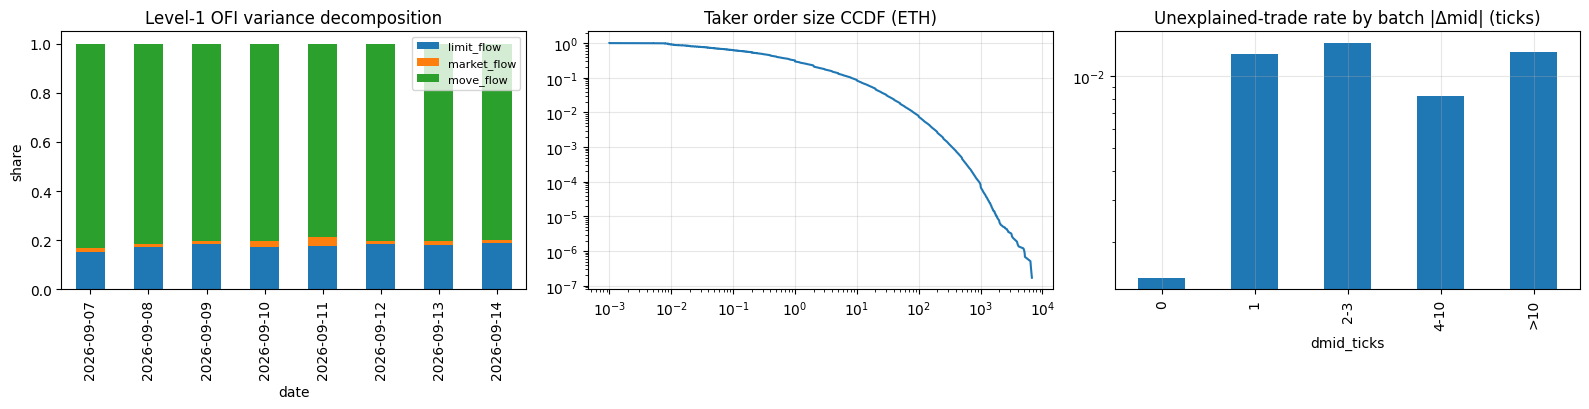

In [8]:
od = pd.concat(order_days, ignore_index=True)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
dec.plot.bar(stacked=True, ax=ax[0]); ax[0].set_title('Level-1 OFI variance decomposition'); ax[0].set_ylabel('share'); ax[0].legend(fontsize=8)
q = np.sort(od.qty.to_numpy() / 1000); ax[1].loglog(q, 1 - np.arange(len(q)) / len(q)); ax[1].set_title('Taker order size CCDF (ETH)'); ax[1].grid(alpha=.3)
b.unexplained_rate.plot.bar(ax=ax[2], logy=True); ax[2].set_title('Unexplained-trade rate by batch |Δmid| (ticks)'); ax[2].grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '03_events.png', dpi=110); plt.show()

In [9]:
lines = ['# 03 · Events and OFI: summary', '',
         f"valid batches: {int(ds.ok.sum()):,} of {int(ds.batches.sum()):,}; identity violations: {int(ds.identity_violations.sum())}",
         f"taker orders: {int(ds.orders.sum()):,}; walk the book in order: worst day {ds.orders_mono.min():.3%}",
         f"OFI variance shares (all days): limit {((ds.s_ol - ds.s_o*ds.s_l/nb)).sum()/((ds.s_oo - ds.s_o**2/nb)).sum():.3f}, "
         f"market {((ds.s_om - ds.s_o*ds.s_m/nb)).sum()/((ds.s_oo - ds.s_o**2/nb)).sum():.3f}, "
         f"move {((ds.s_ov - ds.s_o*ds.s_v/nb)).sum()/((ds.s_oo - ds.s_o**2/nb)).sum():.3f}",
         f"trading-and-growth at the touch: {(ds.trade_growth_b + ds.trade_growth_a).sum()/(ds.touch_trading_b + ds.touch_trading_a).sum():.2%}",
         f"unexplained trades: quiet-batch rate {pv['unexplained'][['0','1']].sum().sum()/pv['trades'][['0','1']].sum().sum():.4%}; "
         f"share in fast batches {pv['unexplained'][['4-10','>10']].sum().sum()/pv['unexplained'].sum().sum():.1%}; "
         f"found within ±{TOL_KMAX} batches {1 - tol.get('k99', pd.Series(0)).sum()/tol.values.sum():.1%}",
         f"hand-check: {'PASS' if hc_ok else 'FAIL'}", '']
lines += [('PASS ' if v else 'FAIL ') + k for k, v in gate0.items()] + ['', f'STAGE 0: {verdict}']
(REP / '03_summary.md').write_text('\n'.join(lines), encoding='utf-8'); print('\n'.join(lines))
print('\nSend me: reports/03_summary.md, 03_day_stats.csv, 03_unexplained_by_dmid.csv, 03_tolerance_scan.csv, 03_handcheck.csv, 03_events.png')

# 03 · Events and OFI: summary

valid batches: 25,206,056 of 25,720,661; identity violations: 0
taker orders: 5,861,027; walk the book in order: worst day 99.685%
OFI variance shares (all days): limit 0.178, market 0.017, move 0.805
trading-and-growth at the touch: 33.83%
unexplained trades: quiet-batch rate 0.2296%; share in fast batches 90.1%; found within ±5 batches 18.8%
hand-check: PASS

PASS notebook 02: every BOOK and TRADES check passed
PASS event identity: level-1 OFI == limit + market + move on every batch
FAIL quiet batches (|Δmid| ≤ 1 tick): unexplained rate ≤ 0.05%, every day
PASS ≥ 80% of unexplained trades in fast batches (|Δmid| ≥ 4 ticks), every day
PASS taker orders walk the book in order ≥ 99%, every day

STAGE 0: NOT PASSED

Send me: reports/03_summary.md, 03_day_stats.csv, 03_unexplained_by_dmid.csv, 03_tolerance_scan.csv, 03_handcheck.csv, 03_events.png
